In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


In [10]:
df = pd.read_csv(r"C:\Users\boppa\OneDrive\Documents\crop-production-prediction\Crop Production.csv")
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (246091, 7)


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 246091 entries, 0 to 246090
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   State_Name     246091 non-null  object 
 1   District_Name  246091 non-null  object 
 2   Crop_Year      246091 non-null  int64  
 3   Season         246091 non-null  object 
 4   Crop           246091 non-null  object 
 5   Area           246091 non-null  float64
 6   Production     242361 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 13.1+ MB


In [12]:
df.describe()

,Crop_Year,Area,Production
count,246091.000000,2.460910e+05,2.423610e+05
mean,2005.643018,1.200282e+04,5.825034e+05
std,4.952164,5.052340e+04,1.706581e+07
min,1997.000000,4.000000e-02,0.000000e+00
25%,2002.000000,8.000000e+01,8.800000e+01
50%,2006.000000,5.820000e+02,7.290000e+02
75%,2010.000000,4.392000e+03,7.023000e+03
max,2015.000000,8.580100e+06,1.250800e+09


In [13]:
print("States   :", df["State_Name"].nunique())
print("Districts:", df["District_Name"].nunique())
print("Crops    :", df["Crop"].nunique())
print("Years    :", df["Crop_Year"].min(), "to", df["Crop_Year"].max())
print("Seasons  :", df["Season"].unique())

States   : 33
Districts: 646
Crops    : 124
Years    : 1997 to 2015
Seasons  : ['Kharif     ' 'Whole Year ' 'Autumn     ' 'Rabi       ' 'Summer     '
 'Winter     ']


In [14]:
df.isnull().sum()

State_Name          0
District_Name       0
Crop_Year           0
Season              0
Crop                0
Area                0
Production       3730
dtype: int64

In [15]:
df.groupby(df["Crop"].str.strip())["Production"].sum().sort_values(ascending=False).head(5)

Crop
Coconut      1.299816e+11
Sugarcane    5.535682e+09
Rice         1.605470e+09
Wheat        1.332826e+09
Potato       4.248263e+08
Name: Production, dtype: float64

In [16]:
for col in ["State_Name", "District_Name", "Season", "Crop"]:
    df[col] = df[col].str.strip()

rows_before = len(df)
df = df.dropna(subset=["Production"])
df = df[df["Area"] > 0]
df = df[df["Crop"] != "Coconut"]
df = df.drop_duplicates().reset_index(drop=True)

print("Rows before:", rows_before, "  Rows after:", len(df))

Rows before: 246091   Rows after: 240403


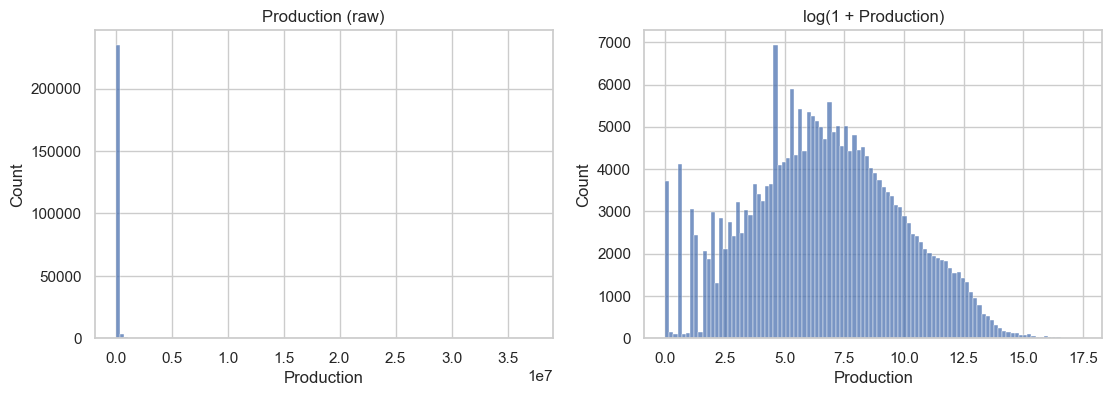

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["Production"], bins=100, ax=axes[0])
axes[0].set_title("Production (raw)")
sns.histplot(np.log1p(df["Production"]), bins=100, ax=axes[1])
axes[1].set_title("log(1 + Production)")
plt.show()

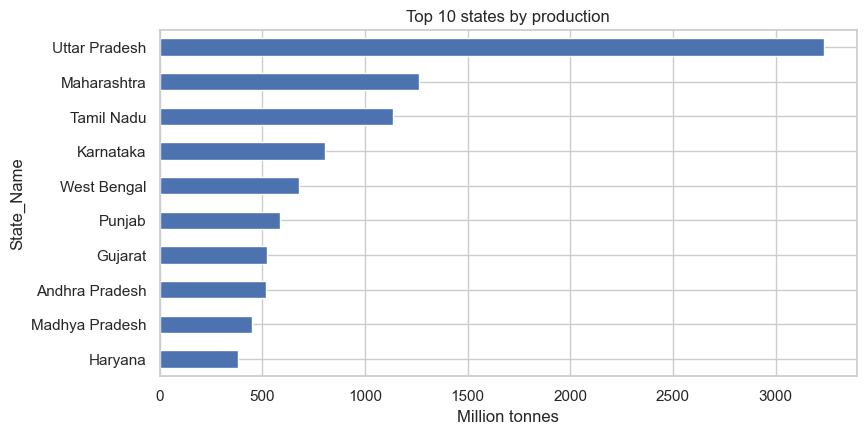

In [18]:
top_states = df.groupby("State_Name")["Production"].sum().sort_values(ascending=False).head(10) / 1e6
top_states.plot(kind="barh", figsize=(9, 4.5)).invert_yaxis()
plt.xlabel("Million tonnes")
plt.title("Top 10 states by production")
plt.show()

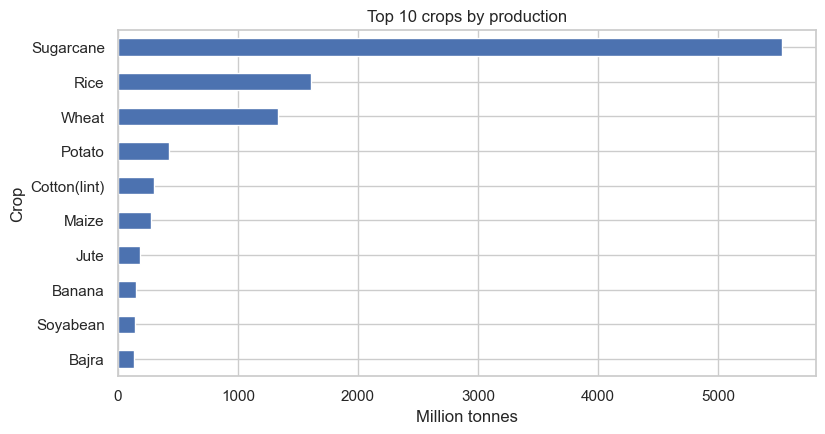

In [19]:
top_crops = df.groupby("Crop")["Production"].sum().sort_values(ascending=False).head(10) / 1e6
top_crops.plot(kind="barh", figsize=(9, 4.5)).invert_yaxis()
plt.xlabel("Million tonnes")
plt.title("Top 10 crops by production")
plt.show()

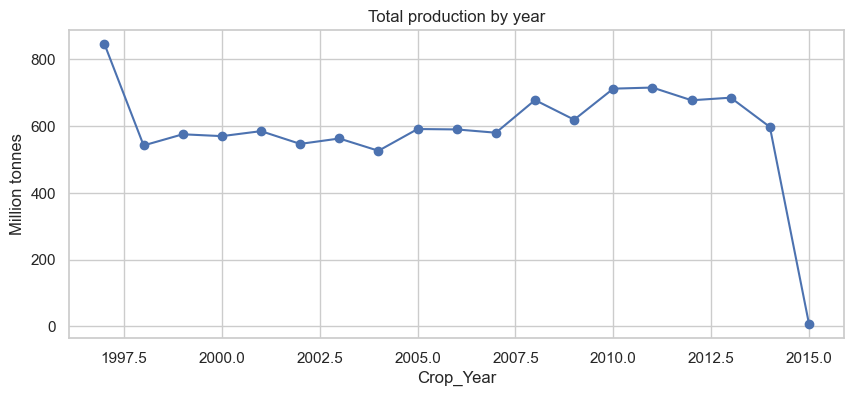

Records in 2015: 561


In [20]:
yearly = df.groupby("Crop_Year")["Production"].sum() / 1e6
yearly.plot(marker="o", figsize=(10, 4))
plt.ylabel("Million tonnes")
plt.title("Total production by year")
plt.show()

print("Records in 2015:", (df["Crop_Year"] == 2015).sum())

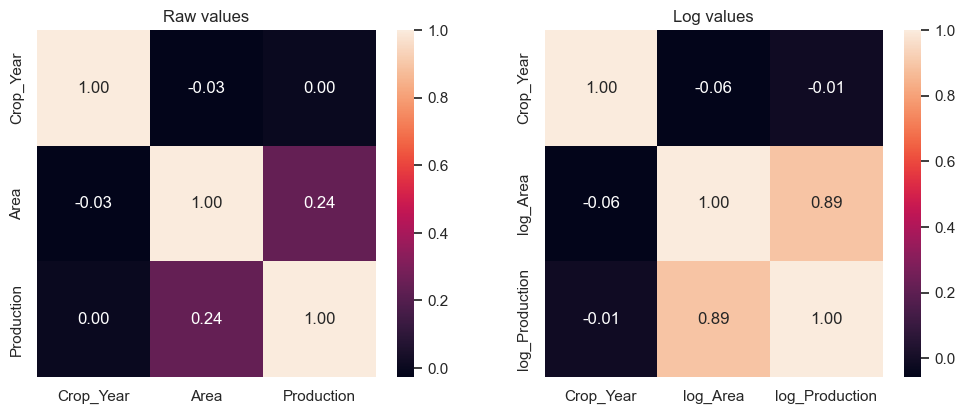

In [21]:
df["log_Area"] = np.log1p(df["Area"])
df["log_Production"] = np.log1p(df["Production"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(df[["Crop_Year", "Area", "Production"]].corr(), annot=True, fmt=".2f", ax=axes[0])
axes[0].set_title("Raw values")
sns.heatmap(df[["Crop_Year", "log_Area", "log_Production"]].corr(), annot=True, fmt=".2f", ax=axes[1])
axes[1].set_title("Log values")
plt.show()

In [22]:
df["District_Crop"] = df["District_Name"] + "_" + df["Crop"]

numeric_cols = ["Crop_Year", "log_Area"]
categorical_cols = ["State_Name", "District_Name", "Season", "Crop"]
features = numeric_cols + categorical_cols + ["District_Crop"]

X = df[features]
y = np.log1p(df["Production"])

print("X shape:", X.shape)
X.head()

X shape: (240403, 7)


,Crop_Year,log_Area,State_Name,District_Name,Season,Crop,District_Crop
0,2000,7.134891,Andaman and Nicobar Islands,NICOBARS,Kharif,Arecanut,NICOBARS_Arecanut
1,2000,1.098612,Andaman and Nicobar Islands,NICOBARS,Kharif,Other Kharif pulses,NICOBARS_Other Kharif pulses
2,2000,4.634729,Andaman and Nicobar Islands,NICOBARS,Kharif,Rice,NICOBARS_Rice
3,2000,5.176150,Andaman and Nicobar Islands,NICOBARS,Whole Year,Banana,NICOBARS_Banana
4,2000,6.580639,Andaman and Nicobar Islands,NICOBARS,Whole Year,Cashewnut,NICOBARS_Cashewnut


In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "  Test:", X_test.shape)

Train: (180302, 7)   Test: (60101, 7)


In [25]:
def linear_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ])

def tree_preprocessor():
    return ColumnTransformer([
        ("num", "passthrough", numeric_cols),
        ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical_cols),
        ("te", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE),
               ["District_Crop", "District_Name", "Crop"]),
    ])

In [27]:
results = {}
predictions = {}

def evaluate(name, y_true_log, y_pred_log):
    y_true = np.expm1(y_true_log)
    y_pred = np.clip(np.expm1(y_pred_log), 0, None)
    scores = {
        "R2 (log)":     r2_score(y_true_log, y_pred_log),
        "RMSE (log)":   np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "MAE (log)":    mean_absolute_error(y_true_log, y_pred_log),
        "R2 (tonnes)":  r2_score(y_true, y_pred),
        "MAE (tonnes)": mean_absolute_error(y_true, y_pred),
    }
    print(name, {k: round(v, 4) for k, v in scores.items()})
    return scores

In [28]:
lr_raw = Pipeline([("prep", linear_preprocessor()), ("model", LinearRegression())])
lr_raw.fit(X_train, np.expm1(y_train))
print("R2 on RAW tonnes:", r2_score(np.expm1(y_test), lr_raw.predict(X_test)))

R2 on RAW tonnes: 0.16063168189393584


In [29]:
lr = Pipeline([("prep", linear_preprocessor()), ("model", LinearRegression())])
lr.fit(X_train, y_train)
predictions["Linear Regression"] = lr.predict(X_test)
results["Linear Regression"] = evaluate("Linear Regression", y_test, predictions["Linear Regression"])

Linear Regression {'R2 (log)': 0.9438, 'RMSE (log)': 0.7464, 'MAE (log)': 0.4888, 'R2 (tonnes)': 0.7969, 'MAE (tonnes)': 14903.7065}


In [30]:
rf = Pipeline([
    ("prep", tree_preprocessor()),
    ("model", RandomForestRegressor(n_estimators=150, min_samples_leaf=3, max_features=0.6,
                                    n_jobs=-1, random_state=RANDOM_STATE))
])
rf.fit(X_train, y_train)
predictions["Random Forest"] = rf.predict(X_test)
results["Random Forest"] = evaluate("Random Forest", y_test, predictions["Random Forest"])

Random Forest {'R2 (log)': 0.9708, 'RMSE (log)': 0.5378, 'MAE (log)': 0.3278, 'R2 (tonnes)': 0.8871, 'MAE (tonnes)': 8425.1071}


In [31]:
xgb_search = RandomizedSearchCV(
    Pipeline([("prep", tree_preprocessor()),
              ("model", XGBRegressor(tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE))]),
    param_distributions={
        "model__n_estimators":     [300, 500, 700, 900],
        "model__learning_rate":    [0.03, 0.05, 0.08, 0.1, 0.15],
        "model__max_depth":        [4, 6, 8, 10],
        "model__min_child_weight": [1, 3, 5],
        "model__subsample":        [0.7, 0.8, 0.9],
        "model__colsample_bytree": [0.7, 0.8, 0.9],
    },
    n_iter=12, cv=3, scoring="r2", random_state=RANDOM_STATE, verbose=1,
)

sample = X_train.sample(60000, random_state=RANDOM_STATE)
xgb_search.fit(sample, y_train.loc[sample.index])

best_params = {k.replace("model__", ""): v for k, v in xgb_search.best_params_.items()}
print("Best parameters:", best_params)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'subsample': 0.7, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.08, 'colsample_bytree': 0.8}


In [32]:
xgb = Pipeline([
    ("prep", tree_preprocessor()),
    ("model", XGBRegressor(**best_params, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE))
])
xgb.fit(X_train, y_train)
predictions["XGBoost"] = xgb.predict(X_test)
results["XGBoost"] = evaluate("XGBoost", y_test, predictions["XGBoost"])

XGBoost {'R2 (log)': 0.979, 'RMSE (log)': 0.456, 'MAE (log)': 0.2885, 'R2 (tonnes)': 0.9248, 'MAE (tonnes)': 8158.5036}


In [33]:
def build_stacking():
    return StackingRegressor(
        estimators=[
            ("lr", Pipeline([("prep", linear_preprocessor()), ("model", LinearRegression())])),
            ("rf", Pipeline([("prep", tree_preprocessor()),
                             ("model", RandomForestRegressor(n_estimators=100, min_samples_leaf=3,
                                       max_features=0.6, n_jobs=-1, random_state=RANDOM_STATE))])),
            ("xgb", Pipeline([("prep", tree_preprocessor()),
                              ("model", XGBRegressor(**best_params, tree_method="hist",
                                        n_jobs=-1, random_state=RANDOM_STATE))])),
        ],
        final_estimator=RidgeCV(),
        cv=3,
    )

stack = build_stacking()
stack.fit(X_train, y_train)
predictions["Stacking Ensemble"] = stack.predict(X_test)
results["Stacking Ensemble"] = evaluate("Stacking Ensemble", y_test, predictions["Stacking Ensemble"])
print("Weights [LR, RF, XGB]:", stack.final_estimator_.coef_.round(3))

Stacking Ensemble {'R2 (log)': 0.979, 'RMSE (log)': 0.4556, 'MAE (log)': 0.2916, 'R2 (tonnes)': 0.9293, 'MAE (tonnes)': 8441.6826}
Weights [LR, RF, XGB]: [-1.000e-03 -1.590e-01  1.162e+00]


In [34]:
comparison = pd.DataFrame(results).T.sort_values("R2 (log)", ascending=False)
comparison.round(4)

,R2 (log),RMSE (log),MAE (log),R2 (tonnes),MAE (tonnes)
Stacking Ensemble,0.9790,0.4556,0.2916,0.9293,8441.6826
XGBoost,0.9790,0.4560,0.2885,0.9248,8158.5036
Random Forest,0.9708,0.5378,0.3278,0.8871,8425.1071
Linear Regression,0.9438,0.7464,0.4888,0.7969,14903.7065


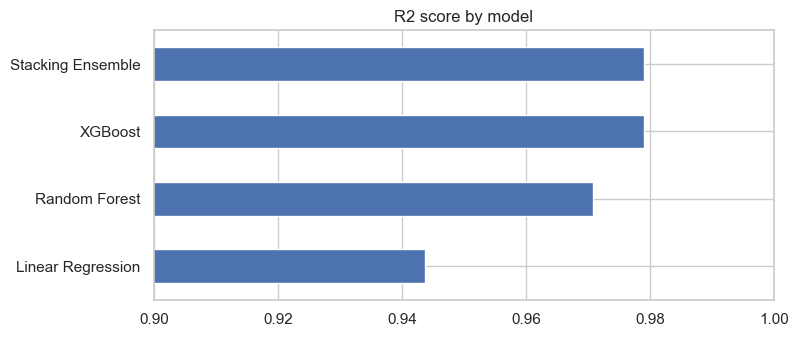

In [35]:
comparison["R2 (log)"].sort_values().plot(kind="barh", figsize=(8, 3.5), xlim=(0.9, 1.0))
plt.title("R2 score by model")
plt.show()

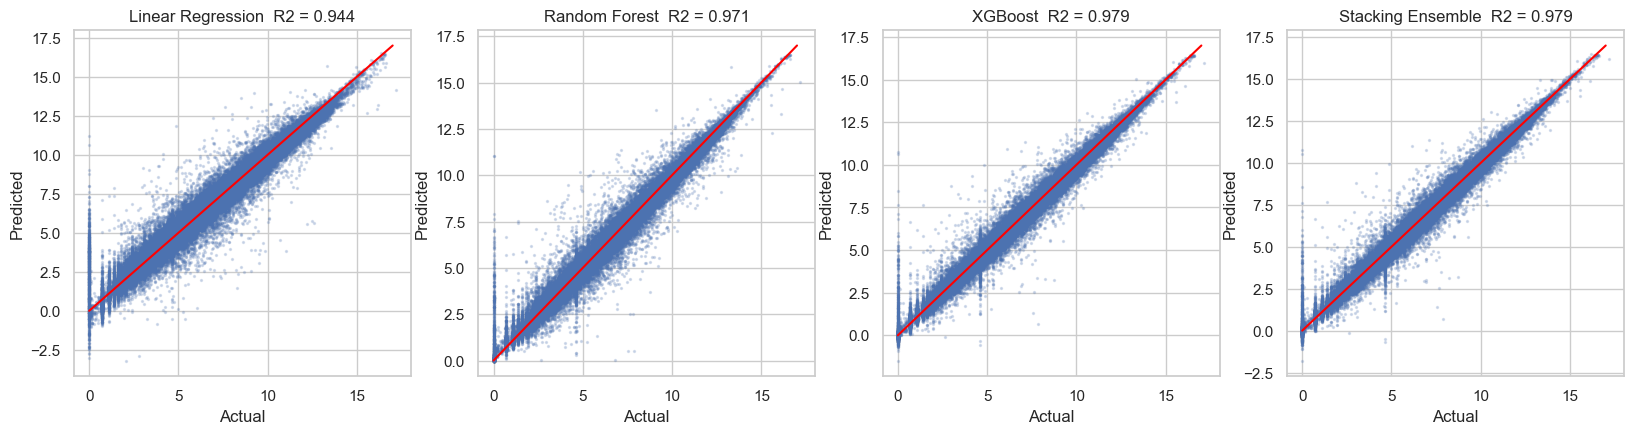

In [37]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, s=2, alpha=0.2)
    ax.plot([0, 17], [0, 17], color="red")
    ax.set_title(f"{name}  R2 = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Actual"); ax.set_ylabel("Predicted")
plt.show()

In [38]:
past = df["Crop_Year"] <= 2010
future = df["Crop_Year"] > 2010

future_models = {
    "Linear Regression": Pipeline([("prep", linear_preprocessor()), ("model", LinearRegression())]),
    "Random Forest": Pipeline([("prep", tree_preprocessor()),
                               ("model", RandomForestRegressor(n_estimators=150, min_samples_leaf=3,
                                         max_features=0.6, n_jobs=-1, random_state=RANDOM_STATE))]),
    "XGBoost": Pipeline([("prep", tree_preprocessor()),
                         ("model", XGBRegressor(**best_params, tree_method="hist",
                                   n_jobs=-1, random_state=RANDOM_STATE))]),
    "Stacking Ensemble": build_stacking(),
}

future_results = {}
for name, model in future_models.items():
    model.fit(X[past], y[past])
    future_results[name] = evaluate(name, y[future], model.predict(X[future]))

pd.DataFrame(future_results).T.sort_values("R2 (log)", ascending=False).round(4)

Linear Regression {'R2 (log)': 0.9538, 'RMSE (log)': 0.6654, 'MAE (log)': 0.4522, 'R2 (tonnes)': 0.8668, 'MAE (tonnes)': 15635.2608}
Random Forest {'R2 (log)': 0.9519, 'RMSE (log)': 0.6788, 'MAE (log)': 0.4227, 'R2 (tonnes)': 0.9186, 'MAE (tonnes)': 13205.5492}
XGBoost {'R2 (log)': 0.9647, 'RMSE (log)': 0.5813, 'MAE (log)': 0.3642, 'R2 (tonnes)': 0.9446, 'MAE (tonnes)': 12049.9835}
Stacking Ensemble {'R2 (log)': 0.9598, 'RMSE (log)': 0.6205, 'MAE (log)': 0.4151, 'R2 (tonnes)': 0.8734, 'MAE (tonnes)': 15185.4059}


,R2 (log),RMSE (log),MAE (log),R2 (tonnes),MAE (tonnes)
XGBoost,0.9647,0.5813,0.3642,0.9446,12049.9835
Stacking Ensemble,0.9598,0.6205,0.4151,0.8734,15185.4059
Linear Regression,0.9538,0.6654,0.4522,0.8668,15635.2608
Random Forest,0.9519,0.6788,0.4227,0.9186,13205.5492


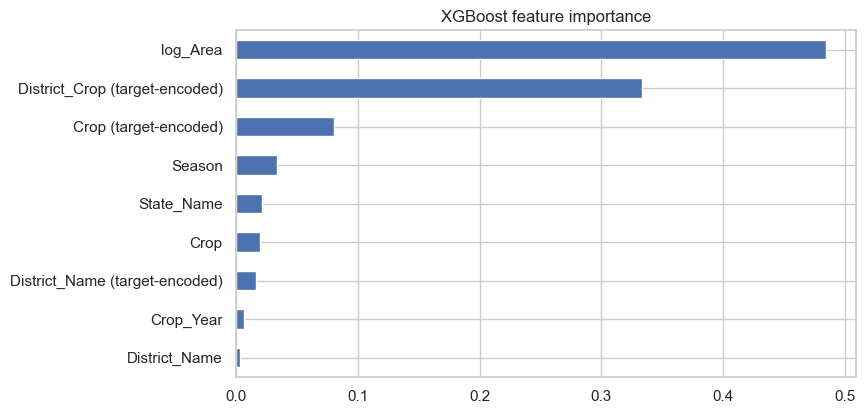

In [47]:
names = xgb.named_steps["prep"].get_feature_names_out()
labels = [n.split("__", 1)[1] + (" (target-encoded)" if n.startswith("te__") else "") for n in names]
importance = pd.Series(xgb.named_steps["model"].feature_importances_, index=labels).sort_values()
importance.plot(kind="barh", figsize=(8, 4.5))
plt.title("XGBoost feature importance")
plt.show()

In [48]:
joblib.dump(xgb, "best_model.joblib")
print("Model saved")

Model saved


In [49]:
def predict_production(state, district, season, crop, year, area):
    row = pd.DataFrame([{
        "Crop_Year": year,
        "log_Area": np.log1p(area),
        "State_Name": state,
        "District_Name": district.upper(),
        "Season": season,
        "Crop": crop,
        "District_Crop": district.upper() + "_" + crop,
    }])
    return float(np.expm1(xgb.predict(row)[0]))

p = predict_production("Punjab", "LUDHIANA", "Rabi", "Wheat", 2014, 250000)
print(f"Predicted wheat production: {p:,.0f} tonnes  ({p/250000:.2f} tonnes per hectare)")

Predicted wheat production: 994,441 tonnes  (3.98 tonnes per hectare)
